# **🌦️ Madar — Smart Weather Monitoring**
**Project goal:** Forecast the **hourly air temperature** at a Saudi weather station for the **next 24 hours**, using the KAPSARC *Saudi Arabia Hourly Climate – Integrated Surface Data* (source: NOAA, 2021-01-01 → 2025-08-25).

**Team decisions (Day 1):**
- Target: `air_temperature` (°C)
- Time step: 1 hour | Forecast horizon: next 24 hours
- Main station: KING KHALED INTL (Riyadh)
- Metrics: MAE (+ RMSE)
- Features: only information known at forecast time (past temperature + hour/day/month)
- Fake values (≥ 99) are set to NaN in `temp`; the raw column is kept
- Split: by date, no shuffling
- One value per hour: keep only the reading at minute 0; an hour without one stays NaN
- Gaps: left as NaN, never filled silently; no forecast window may contain a gap
- Plausible range: -15 to 55 °C (anything outside is treated as an error)

**Problem statement:** We want to forecast the **hourly air temperature** at KING KHALED INTL for the **next 24 hours**, using data available up to the forecast time.

**What success means:** the model must beat a simple baseline (the temperature at the same hour yesterday); a reference goal is a mean error (MAE) below 2 °C. Too-high and too-low errors count the same.

**This notebook covers:** data loading, time structure & quality (A), exploratory plots (B), data problems (C), and domain understanding (D).

## import libraries:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Import DataSet:


In [2]:
PATH = "../raw_data/saudi-hourly-weather-data.csv"
cols = ["station_name", "station_id", "observation_date",
        "air_temperature", "air_temperature_quality"]

df = pd.read_csv(PATH, sep=";", usecols=cols)
df.shape

(1465518, 5)

## Convert the date column


In [3]:
df["observation_date"] = (pd.to_datetime(df["observation_date"], utc=True)
                            .dt.tz_convert("Asia/Riyadh"))
df.dtypes

station_name                                    object
station_id                                       int64
observation_date           datetime64[ns, Asia/Riyadh]
air_temperature                                float64
air_temperature_quality                         object
dtype: object

## Fake values in temperature
Some values are placeholders for missing data (for example 9999.9), not real temperatures.
We do not delete or fill them yet. We keep the raw column `air_temperature`, and create a clean copy `temp` where these values are NaN.
We also record how many there are.

In [4]:
n_fake = (df["air_temperature"] >= 99).sum()
print("fake temperature values:", n_fake)

# the raw column stays as it is, we add a clean copy
df["temp"] = df["air_temperature"].where(df["air_temperature"] < 99)

fake temperature values: 615


## Station coverage
The file contains many weather stations. We need one station for our forecast.
For each station we check:
- rows and unique hours
- first and last date
- `hours_coverage_%`: how many hours exist, compared to all hours between the first and last date
- `missing_temp_%`: share of missing temperatures

We want a station with high coverage, few missing values, and data from 2021 to 2025.

In [5]:
def coverage(g):
    t = g["observation_date"].dt.floor("h")
    expected = int((t.max() - t.min()) / pd.Timedelta(hours=1)) + 1
    return pd.Series({
        "rows": len(g),
        "unique_hours": t.nunique(),
        "first": t.min(),
        "last": t.max(),
        "hours_coverage_%": round(100 * t.nunique() / expected, 1),
        "missing_temp_%": round(100 * g["temp"].isna().mean(), 1),
    })

cov = (df.groupby("station_name").apply(coverage)
         .sort_values("hours_coverage_%", ascending=False))
cov

/tmp/ipykernel_153687/2644106326.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cov = (df.groupby("station_name").apply(coverage)


,rows,unique_hours,first,last,hours_coverage_%,missing_temp_%
station_name,,,,,,
MAKKAH,1,1,2022-07-07 12:00:00+03:00,2022-07-07 12:00:00+03:00,100.0,0.0
KING KHALED MILITARY CITY,1,1,2023-12-14 07:00:00+03:00,2023-12-14 07:00:00+03:00,100.0,0.0
AL-QATIF-GOSP-3,1,1,2023-02-09 06:00:00+03:00,2023-02-09 06:00:00+03:00,100.0,0.0
ABHA,51850,38729,2021-01-01 03:00:00+03:00,2025-08-25 00:00:00+03:00,95.1,0.0
GURIAT,51538,38725,2021-01-01 03:00:00+03:00,2025-08-25 00:00:00+03:00,95.1,0.1
KING KHALED INTL,52024,38719,2021-01-01 03:00:00+03:00,2025-08-25 00:00:00+03:00,95.1,0.0
KING ABDULAZIZ INTL,51819,38729,2021-01-01 03:00:00+03:00,2025-08-25 00:00:00+03:00,95.1,0.0
DAMMAM (KING FAHD INT. AIRPORT),51914,38729,2021-01-01 03:00:00+03:00,2025-08-25 00:00:00+03:00,95.1,0.0
PRINCE MOHAMMAD BIN ABDULAZIZ,51784,38713,2021-01-01 03:00:00+03:00,2025-08-25 00:00:00+03:00,95.1,0.1


In [6]:
# Choose the station (shared)
STATION = "KING KHALED INTL"
s = df[df["station_name"] == STATION].sort_values("observation_date").copy()
s["hour"] = s["observation_date"].dt.floor("h")
print(STATION, "->", len(s), "rows")

KING KHALED INTL -> 52024 rows


# Task A: Time Structure & Data Quality

**Goal:** understand the time axis of the chosen station (format, frequency, duplicates, gaps) and the quality flags, before deciding how to build the hourly series.

> Uses the shared variables from the setup section: `df`, `STATION`, `s` (one station, sorted) and `s["hour"]`.

## A1. Readings per hour and duplicate timestamps
How many readings fall in each hour, how many are at minute 0, and how many timestamps are repeated.

In [7]:
# A1. Readings per hour and duplicate timestamps
per_hour = s.groupby("hour").size()
print("Readings per hour (how many hours have 1, 2, ... readings):")
print(per_hour.value_counts().sort_index())

n_min0 = (s["observation_date"].dt.minute == 0).sum()
print(f"\nReadings at minute 0: {n_min0} of {len(s)}")

# Duplicates: the same exact timestamp appearing more than once
dup_mask = s.duplicated("observation_date", keep=False)
n_extra = s["observation_date"].duplicated().sum()
print(f"Rows sharing a timestamp: {dup_mask.sum()}")
print(f"Extra rows (repeated timestamps): {n_extra}")

d = s[dup_mask].groupby("observation_date")["temp"].agg(["size", "min", "max"])
d["spread"] = d["max"] - d["min"]
print(f"Timestamps repeated exactly twice: {(d['size'] == 2).sum()} of {len(d)}")
print(f"Repeated timestamps with different temperatures: {(d['spread'] > 0).sum()}")
print(d.loc[d["spread"] > 0, "spread"].describe())

Readings per hour (how many hours have 1, 2, ... readings):
1    25604
2    12942
3      157
4       15
5        1
Name: count, dtype: int64

Readings at minute 0: 51527 of 52024
Rows sharing a timestamp: 25618
Extra rows (repeated timestamps): 12809
Timestamps repeated exactly twice: 12809 of 12809
Repeated timestamps with different temperatures: 11439
count    11439.000000
mean         0.278477
std          0.136527
min          0.100000
25%          0.200000
50%          0.300000
75%          0.400000
max          3.300000
Name: spread, dtype: float64


## A2. Date format, time zone and target
Check that the time column is a proper tz-aware datetime, sorted, and that the target is numeric.

In [8]:
# A2. Date format, time zone and target
print("dtype:", s["observation_date"].dtype)
print("Sorted:", s["observation_date"].is_monotonic_increasing)
print("Unique timestamps:", s["observation_date"].is_unique)
print("Duplicated timestamps:", s["observation_date"].duplicated().sum())
print("NaN in date column:", s["observation_date"].isna().sum())   # NOT the same as missing hours (see A3)

n_fake_s = (s["air_temperature"] >= 99).sum()
print("\nTarget dtype:", s["air_temperature"].dtype)
print("Fake values (>= 99) in this station:", n_fake_s)
print(s["temp"].describe())

dtype: datetime64[ns, Asia/Riyadh]
Sorted: True
Unique timestamps: False
Duplicated timestamps: 12809
NaN in date column: 0

Target dtype: float64
Fake values (>= 99) in this station: 1
count    52023.000000
mean        27.951716
std          9.549967
min          1.900000
25%         20.000000
50%         28.800000
75%         35.900000
max         48.000000
Name: temp, dtype: float64


## A3. Period, expected hours and missing hours
Compare the hours we have with a complete hourly calendar from the first to the last hour.

In [9]:
# A3. Start, end, expected hours, missing hours
start, end = s["hour"].min(), s["hour"].max()
full = pd.date_range(start, end, freq="h")
present = pd.DatetimeIndex(s["hour"].unique()).sort_values()
missing = full.difference(present)

print("Start:", start)
print("End:  ", end)
print("Expected hours:", len(full))
print("Hours with at least one reading:", len(present))
print("Missing hours:", len(missing))
print(f"Coverage: {len(present) / len(full):.2%}")

# Hours that exist but have no valid temperature (all readings were fake/NaN)
valid = s.groupby("hour")["temp"].mean().reindex(full)
print("Hours without a valid temperature (missing + fake-only):", valid.isna().sum())

Start: 2021-01-01 03:00:00+03:00
End:   2025-08-25 00:00:00+03:00
Expected hours: 40726
Hours with at least one reading: 38719
Missing hours: 2007
Coverage: 95.07%
Hours without a valid temperature (missing + fake-only): 2007


## A4. Gaps in the time axis
A gap is a jump of more than one hour between two consecutive available hours.

In [10]:
# A4. Gaps in the time axis
gap_df = pd.DataFrame({
    "last_hour_before": present[:-1],
    "first_hour_after": present[1:],
    "time_between": present[1:] - present[:-1],
})
gap_df = gap_df[gap_df["time_between"] > pd.Timedelta("1h")].copy()
gap_df["missing_hours"] = (gap_df["time_between"] / pd.Timedelta("1h")).astype(int) - 1

print("Number of gaps:", len(gap_df))
print("Sum of missing hours in gaps:", gap_df["missing_hours"].sum())   # must equal 'Missing hours' in A3

print("\nGap sizes:")
print(pd.cut(gap_df["missing_hours"], [0, 2, 24, 72, 10_000],
             labels=["1-2 h", "3-24 h", "1-3 days", "> 3 days"]).value_counts().sort_index())

print("\nTop 10 largest gaps:")
print(gap_df.sort_values("missing_hours", ascending=False).head(10).to_string(index=False))

Number of gaps: 235
Sum of missing hours in gaps: 2007

Gap sizes:
missing_hours
1-2 h       179
3-24 h       46
1-3 days      4
> 3 days      6
Name: count, dtype: int64

Top 10 largest gaps:
         last_hour_before          first_hour_after     time_between  missing_hours
2024-11-29 00:00:00+03:00 2025-01-01 03:00:00+03:00 33 days 03:00:00            794
2024-03-27 20:00:00+03:00 2024-04-01 21:00:00+03:00  5 days 01:00:00            120
2024-11-18 00:00:00+03:00 2024-11-22 01:00:00+03:00  4 days 01:00:00             96
2024-02-27 23:00:00+03:00 2024-03-03 00:00:00+03:00  4 days 01:00:00             96
2023-12-29 00:00:00+03:00 2024-01-01 03:00:00+03:00  3 days 03:00:00             74
2021-12-29 00:00:00+03:00 2022-01-01 03:00:00+03:00  3 days 03:00:00             74
2021-02-11 02:00:00+03:00 2021-02-13 13:00:00+03:00  2 days 11:00:00             58
2022-12-30 00:00:00+03:00 2023-01-01 03:00:00+03:00  2 days 03:00:00             50
2021-02-19 15:00:00+03:00 2021-02-21 18:00:00+03:00

## A5. Columns used and their meaning

In [11]:
# A5. Columns used and their meaning
columns_info = pd.DataFrame({
    "column": ["station_name", "station_id", "observation_date",
               "air_temperature", "air_temperature_quality", "temp"],
    "meaning": ["Station name", "Station code", "Observation time (converted to Asia/Riyadh)",
                "Raw air temperature (fake codes >= 99 present)",
                "Quality-control flag of the reading",
                "Cleaned temperature (fake values -> NaN); our target"],
    "unit": ["-", "-", "UTC+3 (local)", "°C", "-", "°C"],
})
columns_info

,column,meaning,unit
0,station_name,Station name,-
1,station_id,Station code,-
2,observation_date,Observation time (converted to Asia/Riyadh),UTC+3 (local)
3,air_temperature,Raw air temperature (fake codes >= 99 present),°C
4,air_temperature_quality,Quality-control flag of the reading,-
5,temp,Cleaned temperature (fake values -> NaN); our ...,°C


## A6. Quality flags and possible measurement changes by year
Look for changes over the years that could signal a different sensor or a change in reporting.

In [12]:
# A6. Quality flags and possible measurement changes by year
year = s["observation_date"].dt.year

print("Quality flags (all years):")
print(s["air_temperature_quality"].value_counts())

print("\nQuality flags by year:")
print(s.groupby(year)["air_temperature_quality"].value_counts().unstack(fill_value=0).T)

print("\nBy year: rows, mean temp, fake values:")
print(pd.DataFrame({
    "rows": s.groupby(year).size(),
    "mean_temp": s.groupby(year)["temp"].mean().round(2),
    "fake_values": s.groupby(year)["air_temperature"].apply(lambda x: (x >= 99).sum()),
}))

Quality flags (all years):
air_temperature_quality
Passed all quality control checks                  51996
Suspect                                               27
Passed gross limits check if element is present        1
Name: count, dtype: int64

Quality flags by year:
observation_date                                  2021   2022   2023   2024  \
air_temperature_quality                                                       
Passed all quality control checks                11410  11564  11471  10046   
Passed gross limits check if element is present      0      0      1      0   
Suspect                                              8      8      8      1   

observation_date                                 2025  
air_temperature_quality                                
Passed all quality control checks                7505  
Passed gross limits check if element is present     0  
Suspect                                             2  

By year: rows, mean temp, fake values:
            

In [13]:
s.loc[s["air_temperature_quality"] == "Suspect", ["observation_date", "air_temperature"]]

,observation_date,air_temperature
1394014,2021-03-24 15:00:00+03:00,38.2
1393093,2021-03-25 15:00:00+03:00,38.3
1307124,2021-06-26 12:00:00+03:00,44.0
1305338,2021-06-28 11:00:00+03:00,45.0
1295130,2021-07-09 12:00:00+03:00,46.4
1295131,2021-07-09 12:00:00+03:00,46.0
1243714,2021-09-03 12:00:00+03:00,44.0
1209968,2021-10-10 10:00:00+03:00,34.0
1126146,2022-01-14 20:00:00+03:00,15.0
1053811,2022-04-05 10:00:00+03:00,37.0


**Reading (Suspect rows):** the 27 `Suspect` readings are plausible for their hour and season (for example 44–46 °C at noon in summer, 15 °C at night in January). Several come in pairs from repeated timestamps. We cannot tell why they were flagged, and nothing shows a measurement error, so they are **kept**. They are spread over the years (8, 8, 8, 1, 2).

## A7. Task A summary table

In [14]:
# A7. Final Task A summary
summary = pd.DataFrame({
    "item": ["Station", "Start", "End", "Expected hours", "Hours with data",
             "Missing hours", "Coverage", "Number of gaps", "Largest gap (missing hours)",
             "Extra duplicate rows", "Fake values (>=99)"],
    "value": [STATION, start, end, len(full), len(present), len(missing),
              f"{len(present) / len(full):.2%}", len(gap_df), gap_df["missing_hours"].max(),
              n_extra, n_fake_s],
})
summary

,item,value
0,Station,KING KHALED INTL
1,Start,2021-01-01 03:00:00+03:00
2,End,2025-08-25 00:00:00+03:00
3,Expected hours,40726
4,Hours with data,38719
5,Missing hours,2007
6,Coverage,95.07%
7,Number of gaps,235
8,Largest gap (missing hours),794
9,Extra duplicate rows,12809


#### Findings (Task A)

- **Time column:** `observation_date` is a tz-aware datetime (Asia/Riyadh), sorted, no NaN. Period: 2021-01-01 03:00 → 2025-08-25 00:00 (KING KHALED INTL, 52,024 rows).
- **Coverage:** 40,726 expected hourly slots, 38,719 have at least one reading, so **2,007 hours are missing (coverage 95.07%)**.
- **Duplicates:** 12,809 timestamps are repeated, **always exactly twice**, and 11,439 of those pairs have different temperatures (median 0.3 °C, max 3.3 °C). Only 51,527 of 52,024 readings are at minute 0. The rule for one value per hour is **agreed: keep the minute-0 reading only** (see the options in C3). Minute-0 only and the average of the hour differ by one hour (2022-05-14 11:00 has no minute-0 reading), which is why Task B counts 2,008 NaN hours.
- **Target:** `air_temperature` is numeric, range 1.9–48.0 °C, median 28.8 °C. **1 fake value** (2023) becomes NaN in `temp`.
- **Gaps:** 235 gaps (179 of 1–2 h, 46 of 3–24 h, 4 of 1–3 days, 6 longer than 3 days). The largest is **794 missing hours (2024-11-29 → 2025-01-01)**. Several gaps sit at the year end (2021, 2022, 2023), which may be a pattern; this is **not confirmed**.
- **Quality flags:** 51,996 passed, 27 `Suspect`, 1 gross-limits (the fake value). No clear change across the years.
- **Nothing was removed, filled or changed.**

# Task B: Plots
## Goal
Show how the hourly air temperature behaves over time: the daily cycle, the yearly pattern, and the gaps. The plots help us choose features and a baseline for the 24-hour forecast.

## Setup (for plotting only)
- Station: KING KHALED INTL (Riyadh).
- We keep only readings at minute 0, and average the repeated ones, to get one value per hour.
- Missing hours stay NaN, so gaps show as breaks in the line. We do not fill them.
- **This is not the final rule.** The rule for one value per hour is decided by the team (task A). If it changes, only this cell changes and the plots update.
- Figures are saved in `reports/figures/`.

In [15]:
# For plotting only: keep minute-0 readings and average repeated ones.
# The final rule for one value per hour is decided by the team (task A).
m0 = s[s["observation_date"].dt.minute == 0]
hourly = m0.groupby("hour")["temp"].mean()
hourly = hourly.reindex(pd.date_range(s["hour"].min(), s["hour"].max(), freq="h"))
# missing hours stay NaN, so gaps show as breaks in the line

import os
os.makedirs("../reports/figures", exist_ok=True)
hourly.shape, hourly.isna().sum()

((40726,), 2008)

In [16]:
only_off_minute = pd.DatetimeIndex(sorted(set(s["hour"]) - set(m0["hour"])))
print(len(only_off_minute), only_off_minute)

1 DatetimeIndex(['2022-05-14 11:00:00+03:00'], dtype='datetime64[ns, Asia/Riyadh]', freq=None)


## Plot 1: Full series
**Question:** Is there a yearly pattern or a trend? Where are the gaps?

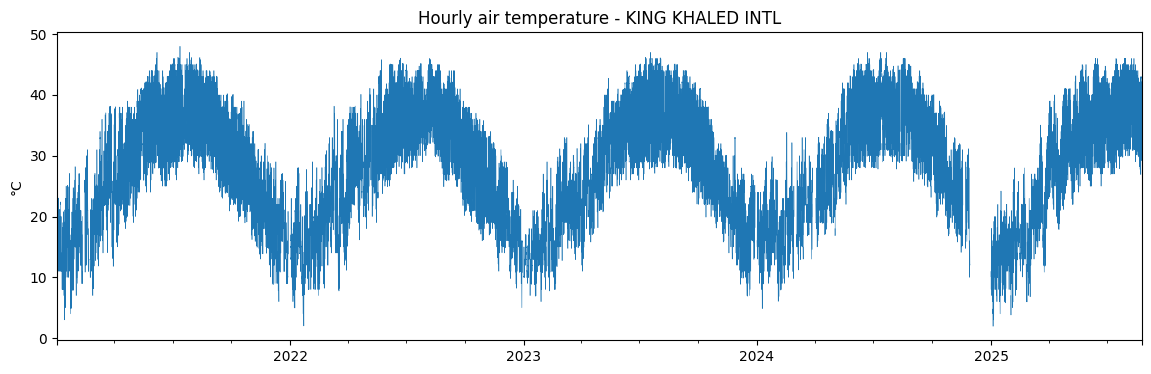

In [17]:
fig, ax = plt.subplots(figsize=(14, 4))
hourly.plot(ax=ax, lw=0.4)
ax.set_title("Hourly air temperature - KING KHALED INTL")
ax.set_ylabel("°C")
fig.savefig("../reports/figures/01_full_series.png", dpi=150, bbox_inches="tight")

## Plot 2: Two-week zoom
**Question:** What does the daily cycle look like in summer and in winter?

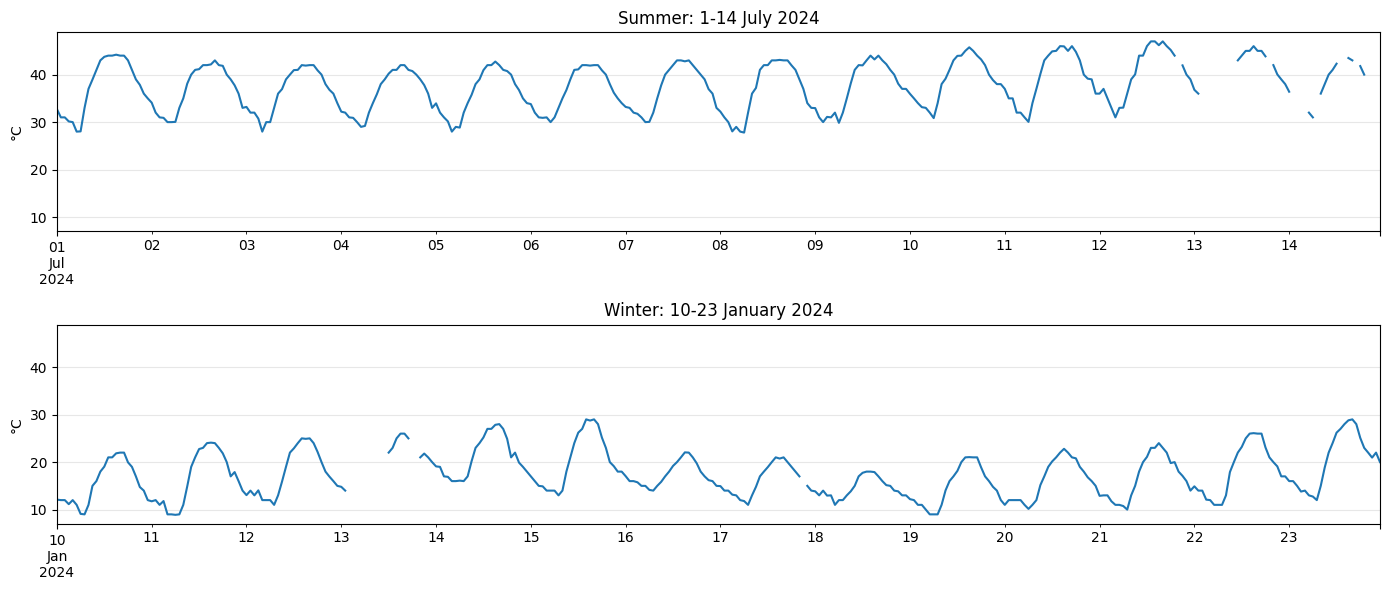

In [18]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharey=True)

hourly.loc["2024-07-01":"2024-07-14"].plot(ax=ax[0], title="Summer: 1-14 July 2024")
hourly.loc["2024-01-10":"2024-01-23"].plot(ax=ax[1], title="Winter: 10-23 January 2024")

for a in ax:
    a.set_ylabel("°C")
    a.grid(alpha=0.3)

plt.tight_layout()
fig.savefig("../reports/figures/02_two_weeks.png", dpi=150, bbox_inches="tight")


## Plot 3: Average by hour of day and by month
**Question:** At what hour is it hottest? Which months are hottest and coldest?

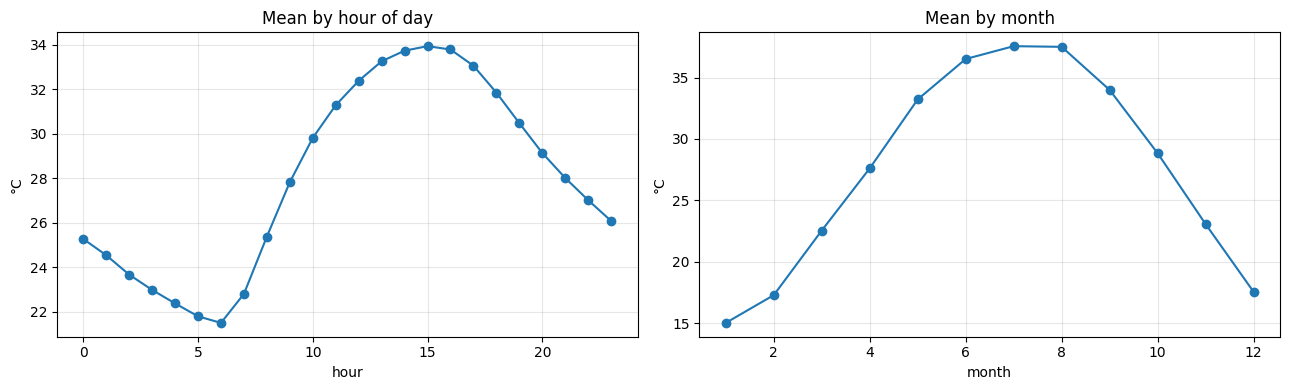

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hourly.groupby(hourly.index.hour).mean().plot(ax=ax[0], marker="o", title="Mean by hour of day")
hourly.groupby(hourly.index.month).mean().plot(ax=ax[1], marker="o", title="Mean by month")
ax[0].set_xlabel("hour"); ax[1].set_xlabel("month")
for a in ax:
    a.set_ylabel("°C")
    a.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("../reports/figures/03_hour_month.png", dpi=150, bbox_inches="tight")

#### Findings (Task B)

- **Yearly pattern (clear):** five summers are visible (2021–2025). Temperature peaks in June–August and is lowest in December–February. Monthly means go from about 15 °C (January) to about 37.5 °C (July–August).
- **Daily pattern (clear):** mean temperature is lowest around 06:00 (about 21.5 °C) and highest around 15:00 (about 34 °C). In the two-week plots every day shows the same shape, in summer (about 28–47 °C) and in winter (about 9–29 °C), with winter about 18 °C lower.
- **Long-term trend:** none visible in 4.6 years (summer peaks reach about 45–48 °C every year). The period is too short to claim a trend.
- **Sudden changes:** no jump or level shift that would suggest a sensor or unit change. We do not explain individual cooler days without a source.
- **Missing periods:** the largest break is at the end of 2024 (794 hours, 2024-11-29 → 2025-01-01). Short gaps appear in the two-week plots. Gaps are not filled.
- **Weekly pattern:** not checked and not expected for temperature; we do not claim one.
- **For the model:** hour of day and month are strong features and are known at forecast time. A "same hour yesterday" baseline is a natural first benchmark (not tested yet).

# Task C: Data Quality

**Goal:** check the whole dataset (all stations) for missing values, duplicate timestamps, impossible values, changes in units or collection, and irregular time intervals, and record the possible impact of each issue on a forecast.

## C1. Data loading and initial inspection
Inspect the structure, size and data types of the full file before running the quality checks.

In [20]:
# C1. Load the full raw file (all stations, all 33 columns)
# Named `raw` so it does not replace the shared `df`
raw = pd.read_csv(PATH, sep=";")
raw.columns = raw.columns.str.lower()   # same column names for everyone

print(f"Dataset shape: {raw.shape}")
display(raw.head())
display(raw.dtypes.to_frame("Data Type"))

Dataset shape: (1465518, 33)


,year,station_country,station_name,station_id,observation_date,elevation,wind_direction_angle,wind_direction_angle_units,wind_direction_quality,wind_type,...,air_temperature,air_temperature_units,air_temperature_quality,air_temperature_dew_point,air_temperature_dew_point_units,air_temperature_dew_point_quality,atmospheric_sea_level_pressure,atmospheric_sea_level_pressure_units,atmospheric_sea_level_pressure_quality,geopoint
0,2025,SA,AL BAHA,41055099999,2025-08-25T00:00:00+03:00,1672.13,240,ANGULAR DEGREES,Passed all quality control checks,Normal,...,25.5,DEGREES CELSIUS,Passed all quality control checks,13.0,DEGREES CELSIUS,Passed all quality control checks,9999.9,HECTOPASCALS,Passed gross limits check if element is present,"20.296139, 41.634277000000004"
1,2025,SA,KING ABDULLAH BIN ABDULAZIZ,41140099999,2025-08-25T00:00:00+03:00,6.09,10,ANGULAR DEGREES,Passed all quality control checks,Normal,...,30.6,DEGREES CELSIUS,Passed all quality control checks,26.0,DEGREES CELSIUS,Passed all quality control checks,1008.7,HECTOPASCALS,Passed all quality control checks,"16.901111, 42.585833"
2,2025,SA,KING ABDULAZIZ INTL,41024099999,2025-08-25T00:00:00+03:00,14.63,170,ANGULAR DEGREES,Passed all quality control checks,Normal,...,33.0,DEGREES CELSIUS,Passed all quality control checks,27.0,DEGREES CELSIUS,Passed all quality control checks,9999.9,HECTOPASCALS,Passed gross limits check if element is present,"21.679564000000003, 39.156535999999996"
3,2025,SA,KING KHALED INTL,40437099999,2025-08-25T00:00:00+03:00,624.53,999,ANGULAR DEGREES,Passed gross limits check if element is present,Calm,...,31.9,DEGREES CELSIUS,Passed all quality control checks,-2.0,DEGREES CELSIUS,Passed all quality control checks,999.8,HECTOPASCALS,Passed all quality control checks,"24.957639999999998, 46.698776"
4,2025,SA,KING KHALED AB,41114099999,2025-08-25T00:00:00+03:00,2065.93,260,ANGULAR DEGREES,Passed all quality control checks,Normal,...,19.1,DEGREES CELSIUS,Passed all quality control checks,15.0,DEGREES CELSIUS,Passed all quality control checks,9999.9,HECTOPASCALS,Passed gross limits check if element is present,"18.297286, 42.803536"


,Data Type
year,int64
station_country,object
station_name,object
station_id,int64
observation_date,object
elevation,float64
wind_direction_angle,int64
wind_direction_angle_units,object
wind_direction_quality,object
wind_type,object


## C2. Data types and timestamp validation

In [21]:
raw["observation_date"] = pd.to_datetime(
    raw["observation_date"],
    errors="coerce",
    utc=True
)

print("Invalid timestamps:", raw["observation_date"].isna().sum())
print("Date range:", raw["observation_date"].min(), "to", raw["observation_date"].max())
print("Number of stations:", raw["station_id"].nunique())

Invalid timestamps: 0
Date range: 2021-01-01 00:00:00+00:00 to 2025-08-24 21:00:00+00:00
Number of stations: 37


## C3. Missing values and unusual readings

In [22]:
original = raw.drop(columns="temp", errors="ignore")   # ignore the clean column added later

missing_summary = pd.DataFrame({
    "Missing Count": original.isna().sum(),
    "Missing (%)": (original.isna().mean() * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing (%)", ascending=False)
)

,Missing Count,Missing (%)


**Reading:** the file has no NaN at all. This does **not** mean there are no missing values: missing measurements are stored as special codes (see the temperature documentation below and the code check later in this section).

## Air temperature: missing and unusual values

In [23]:
# Quality flags only (all stations)
display(
    raw["air_temperature_quality"]
    .value_counts(dropna=False)
    .rename_axis("quality_flag")
    .reset_index(name="Count")
)

# Rows that did not pass the checks (the suspicious ones)
display(
    raw.loc[raw["air_temperature_quality"] != "Passed all quality control checks",
            ["station_name", "observation_date", "air_temperature", "air_temperature_quality"]]
    .sort_values("air_temperature", ascending=False)
    .head(15)
)

,quality_flag,Count
0,Passed all quality control checks,1463710
1,Suspect,1178
2,Passed gross limits check if element is present,615
3,"Passed all quality control checks, data origin...",15


,station_name,observation_date,air_temperature,air_temperature_quality
927392,AL JOUF,2022-08-24 06:00:00+00:00,999.9,Passed gross limits check if element is present
942454,PRINCE ABDULMAJEED BIN ABDULAZIZ AIRPORT,2022-08-07 15:00:00+00:00,999.9,Passed gross limits check if element is present
943415,PRINCE ABDULMAJEED BIN ABDULAZIZ AIRPORT,2022-08-06 14:00:00+00:00,999.9,Passed gross limits check if element is present
944398,HAIL,2022-08-05 12:00:00+00:00,999.9,Passed gross limits check if element is present
944874,PRINCE MOHAMMAD BIN ABDULAZIZ,2022-08-05 00:00:00+00:00,999.9,Passed gross limits check if element is present
944988,PRINCE ABDULMAJEED BIN ABDULAZIZ AIRPORT,2022-08-04 21:00:00+00:00,999.9,Passed gross limits check if element is present
944996,PRINCE MOHAMMAD BIN ABDULAZIZ,2022-08-04 21:00:00+00:00,999.9,Passed gross limits check if element is present
946027,WADI AL DAWASIR,2022-08-03 11:39:00+00:00,999.9,Passed gross limits check if element is present
948151,NEJRAN,2022-08-01 02:00:00+00:00,999.9,Passed gross limits check if element is present
948559,NEJRAN,2022-07-31 15:00:00+00:00,999.9,Passed gross limits check if element is present


#### Air temperature distribution (raw column, before cleaning)


In [24]:
display(raw["air_temperature"].describe().to_frame().T)

,count,mean,std,min,25%,50%,75%,max
air_temperature,1465518.0,26.889188,21.847142,-6.0,20.0,27.0,33.0,999.9


#### Unusual air temperature values:

In [25]:
suspicious_temp = raw["air_temperature"].isin([999.9, 999])

print(f"Suspicious records: {suspicious_temp.sum():,}")
print(f"Percentage: {suspicious_temp.mean() * 100:.2f}%")

Suspicious records: 615
Percentage: 0.04%


#### Data documentation: missing temperature values

The dataset contains 615 suspicious air temperature records (approximately 0.04% of all observations) with values identified as 999.9 or 999. This is the same count as the shared rule `air_temperature >= 99` used in the setup section.

According to NOAA's Integrated Surface Database (ISD) format documentation, the missing-value code for air temperature is +9999, with a scaling factor of 10. This corresponds to 999.9 °C in the processed data.

Therefore, the value 999.9 is treated as a missing-value indicator rather than a real air temperature measurement.

**Decision (agreed by the team):** these records are set to NaN in the clean column `temp`; the original column `air_temperature` is kept for traceability. Nothing is deleted or filled.

**Source:** NOAA National Centers for Environmental Information (NCEI), ISD Format Documentation: https://noaaisd.blob.core.windows.net/noaa-isd/pub/data/noaa/isd-format-document.pdf

#### Impossible values and changes in units


In [26]:
# Units: is the temperature always in the same unit, in every year?
print("Temperature units:")
print(raw["air_temperature_units"].value_counts())
print("\nNumber of different units per year:")
print(raw.groupby(raw["observation_date"].dt.year)["air_temperature_units"].nunique())

# Range: clean temperature (fake codes -> NaN) and look for impossible values
raw["temp"] = raw["air_temperature"].where(raw["air_temperature"] < 99)
LOW, HIGH = -15, 55   # our assumed plausible range for Saudi Arabia in °C (to be confirmed)

print("\nClean temperature:")
print(raw["temp"].describe())
outside = raw[(raw["temp"] < LOW) | (raw["temp"] > HIGH)]
print(f"\nValues outside {LOW} to {HIGH} °C: {len(outside)}")

by_station = raw.groupby("station_name")["temp"].agg(["min", "max"])
print("\nColdest stations:")
print(by_station.sort_values("min").head(5))
print("\nHottest stations:")
print(by_station.sort_values("max", ascending=False).head(5))

Temperature units:
air_temperature_units
DEGREES CELSIUS    1465518
Name: count, dtype: int64

Number of different units per year:
observation_date
2021    1
2022    1
2023    1
2024    1
2025    1
Name: air_temperature_units, dtype: int64

Clean temperature:
count    1.464903e+06
mean     2.648070e+01
std      8.936633e+00
min     -6.000000e+00
25%      2.000000e+01
50%      2.700000e+01
75%      3.300000e+01
max      5.040000e+01
Name: temp, dtype: float64

Values outside -15 to 55 °C: 0

Coldest stations:
              min   max
station_name           
TURAIF       -6.0  45.0
GURIAT       -5.0  47.0
ARAR         -4.0  48.0
RAFHA        -2.0  50.0
AL JOUF      -1.0  47.0

Hottest stations:
                                 min   max
station_name                              
AL AHSA                          4.0  50.4
DAMMAM (KING FAHD INT. AIRPORT)  5.0  50.2
KING ABDULAZIZ AB                6.0  50.0
RAFHA                           -2.0  50.0
QAISUMAH                        -1.0  50.

In [27]:
# Measurement precision: share of whole-degree readings per station (clean temperature)
whole = (raw["temp"] % 1 == 0).astype(float).where(raw["temp"].notna())
precision = whole.groupby(raw["station_name"]).mean().round(2).sort_values()
display(precision.to_frame("share_of_whole_degrees"))

,share_of_whole_degrees
station_name,
K.F.I.A. (KING FAHAD INT. AIRPORT) DAMMA,0.00
ARAFAT,0.21
MINA,0.23
AL-DAWADAMI,0.48
ABHA,0.78
PRINCE MOHAMMAD BIN ABDULAZIZ,0.78
KING KHALED INTL,0.78
KING ABDULLAH BIN ABDULAZIZ,0.78
KING ABDULAZIZ INTL,0.78


In [28]:
# Is the decimal reading linked to repeated timestamps? (our station only)
x = raw[(raw["station_name"] == STATION) & raw["temp"].notna()].copy()
x["is_whole"] = x["temp"] % 1 == 0
x["repeated"] = x.duplicated("observation_date", keep=False)

print("Whole-degree share, repeated timestamps:", round(x.loc[x["repeated"], "is_whole"].mean(), 2))
print("Whole-degree share, unique timestamps:  ", round(x.loc[~x["repeated"], "is_whole"].mean(), 2))

print("\nIn each repeated pair: how many readings are whole degrees?")
pairs = x[x["repeated"]].groupby("observation_date")["is_whole"].sum()
display(pairs.value_counts().sort_index().rename_axis("whole readings in the pair").to_frame("pairs"))

print("\nWhole-degree share by year:")
display(x.groupby(x["observation_date"].dt.year)["is_whole"].mean().round(2).to_frame("share_of_whole_degrees"))

Whole-degree share, repeated timestamps: 0.55
Whole-degree share, unique timestamps:   1.0

In each repeated pair: how many readings are whole degrees?


,pairs
whole readings in the pair,
1,11439
2,1369



Whole-degree share by year:


,share_of_whole_degrees
observation_date,
2021,0.78
2022,0.78
2023,0.78
2024,0.78
2025,0.78


In [29]:
# What else differs inside a repeated pair? (our station)
pair = raw[raw["station_name"] == STATION]
pair = pair[pair.duplicated("observation_date", keep=False)]
cols = [c for c in pair.columns
        if c not in ["observation_date", "temp", "geopoint", "elevation", "station_country", "year"]]
differs = pair.groupby("observation_date")[cols].nunique(dropna=False).gt(1).mean().round(2)
display(differs[differs > 0].sort_values(ascending=False).to_frame("share_of_pairs_that_differ"))

# Which record of the pair has a sea-level pressure value?
mixed = pair[pair["temp"].notna()].copy()
mixed["is_whole"] = mixed["temp"] % 1 == 0
mixed["has_pressure"] = mixed["atmospheric_sea_level_pressure"] != 9999.9
display(mixed.groupby("is_whole")["has_pressure"].mean().round(2).to_frame("share_with_pressure"))

,share_of_pairs_that_differ
atmospheric_sea_level_pressure,1.00
atmospheric_sea_level_pressure_quality,1.00
air_temperature,0.89
visibility_distance,0.86
sky_cavok,0.75
visibility_distance_quality,0.75
sky_ceiling_height,0.31
sky_ceiling_quality,0.24
sky_ceiling_determination,0.03


,share_with_pressure
is_whole,
False,1.0
True,0.1


**Finding (why precision is mixed, our station):**

- Timestamps that appear once hold only **whole-degree** readings (100%). Every repeated timestamp contains **at least one whole-degree reading**: 11,439 pairs have one whole-degree and one tenth-degree reading, and 1,369 pairs have two identical whole-degree readings.
- Inside a repeated pair the two records differ in **sea-level pressure (100% of pairs)**, temperature (89%), visibility (86%), CAVOK (75%) and ceiling height (31%). Wind and dew point are almost always identical.
- **All 11,439 tenth-degree readings come with a pressure value**, against about 10% of the whole-degree readings. So each repeated pair looks like **two records for the same hour: a basic one (whole degrees, usually no pressure) and a fuller one (tenths and pressure)**. This also explains why pressure is missing in 82.5% of all rows.
- The share of whole-degree readings is **0.78 in every year (2021–2025)**: no change in the measurement process over time.
- **Not verified:** the name of each report type, and why the difference reaches 3.3 °C in some pairs.
- **Team decision (one value per hour): (1) minute-0 only.** The other options were (2) average of the hour, (3) keep the whole-degree record (same precision for every hour, 1 °C) and (4) keep the tenth-degree record when it exists (more precise, but precision varies along the series). Minute-0 is the simplest and most transparent rule; the hours without a minute-0 reading stay NaN (2,008 NaN hours in our station).

#### Missing-value codes in the other columns:

In [30]:
# Count the ISD missing-value codes in each numeric measurement column
codes = {
    "wind_direction_angle": 999,
    "wind_speed_rate": 999.9,
    "sky_ceiling_height": 99999,
    "visibility_distance": 999999,
    "air_temperature": 999.9,
    "air_temperature_dew_point": 999.9,
    "atmospheric_sea_level_pressure": 9999.9,
}

rows = []
for col, code_value in codes.items():
    n = int((raw[col] == code_value).sum())
    rows.append({"column": col, "missing_code": code_value,
                 "rows": n, "share_%": round(100 * n / len(raw), 2)})

display(pd.DataFrame(rows))

,column,missing_code,rows,share_%
0,wind_direction_angle,999.0,171164,11.68
1,wind_speed_rate,999.9,352,0.02
2,sky_ceiling_height,99999.0,1180796,80.57
3,visibility_distance,999999.0,290,0.02
4,air_temperature,999.9,615,0.04
5,air_temperature_dew_point,999.9,3787,0.26
6,atmospheric_sea_level_pressure,9999.9,1209018,82.50


#### Findings (C3: missing values and unusual readings)

- **No NaN in any of the 33 columns**, but missing measurements are stored as NOAA ISD codes (999.9, 999, 9999.9, ...). A NaN check alone would wrongly say the data is complete.
- **Air temperature:** 615 rows (0.04%) hold the missing code 999.9. All of them carry the quality flag `Passed gross limits check if element is present` (615 rows have this flag), so **the quality flag does not mark them as errors**; we must detect them by value.
- **Quality flags:** 1,463,710 rows passed all checks, 1,178 are `Suspect`, 615 are the fake codes above, and 15 carry a combined flag that starts with `Passed all quality control checks`. The `Suspect` rows are **kept for now**.
- **Units:** one unit only (`DEGREES CELSIUS`) in all rows and in every year 2021–2025, so there is no change of units.
- **Range after cleaning:** from -6.0 °C (Turaif) to 50.4 °C (Al Ahsa). **0 values** outside our assumed range of -15 to 55 °C (to be confirmed by the team). The coldest values come from northern stations and the hottest from eastern ones, which is plausible.
- **Measurement precision differs between stations:** the share of readings in whole degrees is 1.00 in 7 stations (for example Makkah, Jubail, Riyadh AB), about 0.78–0.85 in most stations (ours: 0.78), and low in Dammam K.F.I.A. (0.00), Arafat (0.21), Mina (0.23) and Al-Dawadami (0.48). If whole-degree values are rounded, they carry up to ±0.5 °C of rounding error, which matters when comparing MAE between stations.
- **Other columns (all stations):** `atmospheric_sea_level_pressure` is missing in 82.50% of rows and `sky_ceiling_height` in 80.57%, so they are not usable as features. `wind_direction_angle` is missing in 11.68%. Wind speed, visibility and dew point are missing in 0.3% or less.
- **Impact on a forecast:** the 615 fake values are rare but would destroy the target and any scaling if left as numbers, so they become NaN in `temp` (raw column kept, nothing deleted or filled). Pressure and ceiling should not be used as inputs.

## C4. Duplicate records

In [31]:
# Check fully duplicated rows (all 33 columns identical)
duplicates = raw.duplicated().sum()

print(f"Duplicate rows: {duplicates:,}")
print(f"Percentage: {duplicates / len(raw) * 100:.2f}%")

Duplicate rows: 0
Percentage: 0.00%


#### Duplicate station timestamps

In [32]:
# Check duplicate station timestamps (same station, same time)
duplicates = raw.duplicated(
    subset=["station_id", "observation_date"]
)
print(f"Duplicate station timestamps (extra rows): {duplicates.sum():,}")
print(f"Percentage: {duplicates.mean() * 100:.2f}%")

Duplicate station timestamps (extra rows): 332,484
Percentage: 22.69%


In [33]:
# Count duplicate timestamps by station
duplicate_summary = (
    raw[raw.duplicated(["station_id", "observation_date"], keep=False)]
    .groupby(["station_id", "station_name"])
    .size()
    .reset_index(name="Duplicate Records")
    .sort_values("Duplicate Records", ascending=False)
)
display(duplicate_summary.head(10))

,station_id,station_name,Duplicate Records
2,40360099999,GURIAT,25624
12,40415099999,DAMMAM (KING FAHD INT. AIRPORT),25622
1,40357099999,ARAR,25622
15,40437099999,KING KHALED INTL,25618
9,40401099999,PRINCE ABDULMAJEED BIN ABDULAZIZ AIRPORT,25606
13,40420099999,AL AHSA,25600
8,40400099999,WEJH,25596
17,41024099999,KING ABDULAZIZ INTL,25592
6,40375099999,TABUK,25592
14,40430099999,PRINCE MOHAMMAD BIN ABDULAZIZ,25592


In [34]:
# Count records per station and timestamp
records_per_hour = (
    raw.groupby(["station_id", "observation_date"])
    .size()
    .value_counts()
    .sort_index()
)
display(records_per_hour.rename_axis("Records per timestamp").to_frame("Number of timestamps"))

,Number of timestamps
Records per timestamp,
1,800552
2,332480
3,2


**Reading:** most timestamps have one record, 332,480 have two records and 2 have three. That gives 332,482 repeated timestamps and 332,484 extra rows (this is why the two numbers above differ).

#### Investigating duplicate station timestamps

Although no fully duplicated rows were found, many station-timestamp combinations contain multiple records. We compare the air temperature values within these groups to see whether the repeats are identical or different measurements.

In [35]:
# Compare temperatures within duplicate station timestamps
duplicate_groups = raw[
    raw.duplicated(["station_id", "observation_date"], keep=False)
]

temperature_check = (
    duplicate_groups
    .groupby(["station_id", "observation_date"])["air_temperature"]
    .agg(["count", "nunique"])
)
print("Duplicate groups:", len(temperature_check))
print("Groups with different temperatures:", (temperature_check["nunique"] > 1).sum())
print("Groups with identical temperatures:", (temperature_check["nunique"] == 1).sum())

Duplicate groups: 332482
Groups with different temperatures: 256010
Groups with identical temperatures: 76472


**Findings:**

- 332,482 station-timestamp groups contain multiple records.
- 256,010 groups have different air temperature values (for our station, KING KHALED INTL, the repeats differ by a median of 0.3 °C and at most 3.3 °C; see Task A).
- 76,472 groups have identical air temperature values.

Most duplicate groups contain different temperature values, so they cannot simply be dropped. A rule for one value per hour must be agreed first.

#### Duplicate record investigation

We compare the air temperature quality flags inside the duplicate groups to understand the differences.

In [36]:
# Compare temperature quality flags in duplicate groups
duplicate_quality = (
    duplicate_groups
    .groupby(["station_id", "observation_date"])[
        "air_temperature_quality"
    ]
    .nunique()
)
print("Groups with different quality flags:", (duplicate_quality > 1).sum())
print("Groups with identical quality flags:", (duplicate_quality == 1).sum())

Groups with different quality flags: 615
Groups with identical quality flags: 331867


**Additional findings:**

- 615 duplicate groups have different air temperature quality flags.
- 331,867 groups have identical quality flags.

The quality flags differ in only a small number of groups, so they do not explain most duplicate timestamps. The number 615 is the same as the number of fake temperature values; the next check tests whether they are related.

**Question:** are the fake temperature values (999.9) located inside duplicated timestamps?

In [37]:
# Are the fake temperature values inside duplicated station timestamps?
is_dup = raw.duplicated(["station_id", "observation_date"], keep=False)
is_fake = raw["air_temperature"] >= 99

print("Fake temperature values:", int(is_fake.sum()))
print("Fake values inside duplicated timestamps:", int((is_fake & is_dup).sum()))

Fake temperature values: 615
Fake values inside duplicated timestamps: 414


#### Findings (C4: duplicate records)

- **0 fully duplicated rows**, but **332,484 extra rows (22.69%)** share a station and a timestamp with another row: 800,552 timestamps have 1 record, 332,480 have 2 and 2 have 3. The repeats are spread evenly over the stations (about 25,600 rows each in the top 10), so this looks like a feature of the data source, not one faulty station (top 10 only; the other stations were not listed).
- In **256,010 groups (77%)** the repeated records have **different** air temperatures, and in 76,472 groups they are identical. So duplicates cannot simply be dropped.
- For our station, repeated timestamps are a **basic record plus a fuller record with pressure** (see the finding in C3). This is likely the same for the other stations, but only our station was checked.
- Quality flags differ inside only **615 groups**, so they do not explain most duplicates.
- Of the **615 fake values (999.9)**, **414 are inside duplicated timestamps** (a second record exists for the same hour) and **201 are not** (nothing can replace them). The two "615" numbers (flags and fake values) are a coincidence, not the same rows.
- **Impact on a forecast:** with two rows per hour a lag of 24 rows is not 24 hours. We need one value per hour. The rule must ignore fake values, so it does not choose 999.9 when a real reading exists for the same time. The agreed rule is **minute-0 only**, applied after fake values are set to NaN. Hours without a minute-0 reading stay NaN and are not filled.

## C5. Hourly data consistency

Check whether each weather station has regular observations and identify gaps. Intervals are measured between exact timestamps (after dropping repeated timestamps), so extra readings at odd minutes create intervals shorter than one hour.

In [38]:
# Check time intervals for each station
hourly_check = (
    raw.drop_duplicates(["station_id", "observation_date"])
    .sort_values(["station_id", "observation_date"])
    .groupby("station_id")["observation_date"]
    .diff()
)

print("Time gaps greater than one hour:", (hourly_check > pd.Timedelta(hours=1)).sum())
print("Intervals shorter than one hour:", (hourly_check < pd.Timedelta(hours=1)).sum())

Time gaps greater than one hour: 34010
Intervals shorter than one hour: 13492


**Findings:**

- 34,010 intervals exceed one hour (all stations together), indicating gaps in the hourly observations. For our station, Task A found 235 gaps and 2,007 missing hours.
- 13,492 intervals are shorter than one hour, caused by extra readings at minutes other than 0.

No records have been removed or modified.

In [39]:
# Find the maximum time gap for each station
max_gaps = (
    raw.drop_duplicates(["station_id", "observation_date"])
    .sort_values(["station_id", "observation_date"])
    .groupby(["station_id", "station_name"])["observation_date"]
    .apply(lambda s: s.diff().max())
    .sort_values(ascending=False)
)

display(max_gaps.rename("Maximum Time Gap").to_frame().head(10))
print("Largest gap in the whole dataset:", max_gaps.iloc[0], "| station:", max_gaps.index[0][1])

,,Maximum Time Gap
station_id,station_name,
40417099999,K.F.I.A. (KING FAHAD INT. AIRPORT) DAMMA,457 days 06:00:00
41031099999,MINA,330 days 15:00:00
41032099999,ARAFAT,330 days 03:00:00
40419499999,JUBAIL,166 days 03:11:00
40438099999,RIYADH AB,47 days 22:00:00
40430099999,PRINCE MOHAMMAD BIN ABDULAZIZ,33 days 03:00:00
40435099999,AL-DAWADAMI,33 days 03:00:00
40439099999,YENBO,33 days 03:00:00
41024099999,KING ABDULAZIZ INTL,33 days 03:00:00


Largest gap in the whole dataset: 457 days 06:00:00 | station: K.F.I.A. (KING FAHAD INT. AIRPORT) DAMMA


#### Findings (C5: gaps by station)

- **Largest gap in the dataset: 457 days 06:00** (station `K.F.I.A. (KING FAHD INT. AIRPORT) DAMMA`). Mina and Arafat have 330 days and Jubail 166 days, so some stations do not provide continuous data.
- **Five stations show exactly 33 days 03:00 as their largest gap**, the same length as our station's gap (794 missing hours, 2024-11-29 to 2025-01-01). This is **likely the same outage** across many stations, but the dates were not checked for the other stations.
- Dammam airport appears under two station names and ids (`40415099999` and `40417099999`). It is probably the same airport; this is **not verified**.
- **Impact on a forecast:** gaps break lag features and can fall inside the test period, so they must not be filled silently. No records were removed or modified.

## C6. Data quality summary and impact on the forecast

In [40]:
# Summarize the main data quality findings and their possible impact on a forecast
quality_summary = pd.DataFrame({
    "Issue": [
        "Missing values (NaN)",
        "Suspicious air temperature values (999 / 999.9)",
        "Fully duplicated rows",
        "Duplicate station-timestamp groups",
        "Groups with different temperatures",
        "Intervals longer than one hour",
        "Intervals shorter than one hour"
    ],
    "Count": [
        int(raw.drop(columns="temp", errors="ignore").isna().sum().sum()),
        int(raw["air_temperature"].isin([999, 999.9]).sum()),
        int(raw.duplicated().sum()),
        len(temperature_check),
        int((temperature_check["nunique"] > 1).sum()),
        int((hourly_check > pd.Timedelta(hours=1)).sum()),
        int((hourly_check < pd.Timedelta(hours=1)).sum())
    ],
    "Possible impact on a forecast": [
        "None directly, but missing data hides as codes (999.9) and as missing hours.",
        "Left as numbers they would destroy the target and any scaling. Set to NaN in `temp` (1 value in our station).",
        "None.",
        "Two rows for one hour: a lag of 24 rows would not be 24 hours. We need one value per hour.",
        "The chosen rule changes some values slightly (our station: median 0.3 °C, max 3.3 °C).",
        "Gaps break lag features (same hour yesterday) and can fall inside the test period. Do not fill silently.",
        "Extra readings at odd minutes. Use one value per hour."
    ]
})
pd.set_option("display.max_colwidth", None)
display(quality_summary)

,Issue,Count,Possible impact on a forecast
0,Missing values (NaN),0,"None directly, but missing data hides as codes (999.9) and as missing hours."
1,Suspicious air temperature values (999 / 999.9),615,Left as numbers they would destroy the target and any scaling. Set to NaN in `temp` (1 value in our station).
2,Fully duplicated rows,0,None.
3,Duplicate station-timestamp groups,332482,Two rows for one hour: a lag of 24 rows would not be 24 hours. We need one value per hour.
4,Groups with different temperatures,256010,"The chosen rule changes some values slightly (our station: median 0.3 °C, max 3.3 °C)."
5,Intervals longer than one hour,34010,Gaps break lag features (same hour yesterday) and can fall inside the test period. Do not fill silently.
6,Intervals shorter than one hour,13492,Extra readings at odd minutes. Use one value per hour.


### Summary and recommendations

- **Missing values:** no NaN and no fully duplicated rows, but missing measurements are stored as ISD codes, not NaN. Pressure (82.50%) and sky ceiling (80.57%) are almost always missing, so they are not usable as features.
- **Fake temperatures:** 615 records (0.04%) with 999.9. By the NOAA ISD documentation they mean "missing". Their quality flag still says `Passed gross limits check if element is present`, so they must be detected by value. They are set to NaN in `temp`; the raw column is kept (1 of them is in our station).
- **Units and range:** one unit (`DEGREES CELSIUS`) in every year. After cleaning, temperatures go from -6.0 °C to 50.4 °C, with 0 values outside -15 to 55 °C.
- **Duplicates:** 332,482 station-timestamp groups have more than one record (22.69% extra rows), and 256,010 of them have different temperatures. For our station each pair is a basic whole-degree record plus a fuller record with tenths and pressure. 414 of the 615 fake values sit inside duplicated timestamps, so the rule for one value per hour must not pick a fake value when a real one exists.
- **Time intervals:** 34,010 intervals are longer than one hour and 13,492 shorter. The largest gap is 457 days (Dammam, `K.F.I.A.`), and Mina and Arafat have 330 days. Five stations share a largest gap of exactly 33 days 03:00, the same length as our station's gap, which is likely the same outage (dates not checked).

No records have been removed, filled or modified during this assessment.

### Team decisions taken at the end of Day 1

1. **One value per hour:** keep the reading at minute 0 only. Fake values (999.9) are already NaN, so they are never chosen. Hours without a minute-0 reading stay NaN.
2. **Gaps:** left as NaN, no silent filling. The 794-hour gap (2024-11-29 to 2025-01-01) is not filled, and no training or test window may contain it.
3. **Plausible range:** -15 to 55 °C is confirmed (observed -6.0 to 50.4, with 0 values outside).

### Still open (not blocking Day 2)

1. **Suspect flags:** 1,178 air temperature rows are flagged `Suspect` (27 in our station). They are kept for now; do we inspect them further?
2. **Dammam airport** appears under two station ids (`40415099999` and `40417099999`). Is it the same airport? (Not verified; it does not affect our station.)


# Task D: Problem and Domain

> **Draft written from the Day 1 results.** Tags: **[data]** = seen in our checks, **[general]** = general weather knowledge, not verified with this dataset, **[suspected]** = we think so but have not checked. If a teammate has a different D, compare and merge.

## D1. How the target is measured and what can affect it

- **Target:** `air_temperature`, the air temperature at the station in °C, one hourly observation per timestamp (NOAA Integrated Surface Database, distributed by KAPSARC). **[data]** The unit is `DEGREES CELSIUS` in every row and every year.
- **Station:** KING KHALED INTL (Riyadh), elevation 624.53 m, about 24.96° N, 46.70° E. **[data]** (first rows of C1)
- **Time:** timestamps carry `+03:00` (Saudi time). **[data]** Saudi Arabia does not use daylight saving time, so the hour of day is stable through the year. **[general]**
- **Records:** a timestamp can hold two records, a basic whole-degree one and a fuller one with tenths and pressure. **[data]** (our station, see C3)
- **What affects temperature:** time of day, season, cloud cover, wind and dust events, rain and humidity. **[general]** Of these, only wind and dew point exist as columns, and we do not use them as inputs for now.

## D2. Which inputs will really be known at forecast time

We forecast the next 24 hours from the data available up to time *t*.

| Input | Known at forecast time? | Decision |
|---|---|---|
| Past temperature (up to *t*) | Yes | **Use** (lags such as the same hour yesterday) |
| Hour, day and month of the hour we predict | Yes, the calendar is known in advance | **Use** |
| Future temperature | No | Never use it |
| Past wind, dew point, visibility | Past values only | Not for now; maybe later as past values |
| Sea-level pressure, sky ceiling | Past values only, but missing in 82.50% and 80.57% of rows (all stations) **[data]** | Do not use |
| Quality flags | Describe past data only | Not features |

**Rule:** if a column will not be known when the forecast is made, we do not use it. Wind direction (missing 11.68%) and dew point (0.26%) are the columns that could be added later, as past values only.

## D3. Real-world events and changes to keep in mind

- **Missing periods:** a gap of 794 hours from 2024-11-29 to 2025-01-01, and shorter gaps at the end of 2021, 2022 and 2023. **[data]** The year-end pattern may come from how the data was collected or exported, but we have no source. **[suspected]**
- **Measurement process:** the share of whole-degree readings is 0.78 in every year, so we see **no change in the measurement process over time**. **[data]** We have no information about sensor changes.
- **Weather events:** heat in June–August and a mild winter are clear in the plots. **[data]** Sandstorms and rare rain can change the temperature quickly. **[general]** Some cooler days in the plots may come from such events, but we have not checked them. **[suspected]**

## D4. Expectations to compare with the results later

Written before modeling, so we can check them afterwards.

1. The daily cycle keeps its shape: lowest around 06:00 and highest around 15:00. **[data]** (to check on the test period)
2. The yearly cycle keeps its shape: hottest in July–August and coldest in January. **[data]**
3. There is no weekly pattern in temperature; the weekday means should be almost equal. **[suspected]** (to check, not assumed)
4. The "same hour yesterday" baseline is strong in summer, when days are alike, and weaker in spring, autumn and winter, when the weather changes more from day to day. **[suspected]**
5. The error grows with the horizon: the forecast for the next hour is better than for 24 hours ahead. **[suspected]**
6. Errors may be larger right after a gap, because the lags are missing or filled. **[suspected]**
7. A model with an MAE below the rounding level of whole-degree readings (about 0.25 °C) would be suspicious. **[general]**
8. The test period must not contain the 794-hour gap without a decision from the team.

## D5. What the team agrees on

| Item | Status |
|---|---|
| Target: `air_temperature` (°C) | Agreed |
| Time step: 1 hour | Agreed |
| Horizon: the next 24 hours | Agreed |
| Metric: MAE (main, in °C) and RMSE. No MAPE: the zero of the Celsius scale is arbitrary and winter values come close to it (our station reaches 1.9 °C) | Agreed |
| Inputs: only information known at forecast time | Agreed |
| Split: by date, no random shuffle | Agreed |
| Fake values (>= 99) become NaN in `temp`; the raw column is kept | Agreed |
| A forecast is useful if it beats the baseline "same hour yesterday"; reference goal: MAE below 2 °C | Agreed |
| Too-high and too-low errors count the same (so MAE is the main metric) | Agreed |
| One value per hour: minute-0 reading only; an hour without one stays NaN | Agreed |
| Gaps stay NaN, no silent filling; the 794-hour gap is excluded from training and test windows | Agreed |
| Plausible range of -15 to 55 °C | Agreed |